In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'tensorflow', 'keras', 'protobuf', 'ml-dtypes', 'tensorflow-probability', 'tf-keras']
imports = {'pillow': 'PIL', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes', 'tensorflow-probability': 'tensorflow_probability', 'tf-keras': 'tf_keras'}
pinned = {'tensorflow-probability': ('0.25.0', 'tensorflow-probability[tf]==0.25.0', 'tensorflow-probability[tf]==0.25.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'keras': 'keras==3.14.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4', 'tf-keras': 'tf-keras==2.21.0'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'tensorflow.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Probability and Statistics

The previous sections gave us the tools to compute a prediction, a loss, and
its gradient. Once a model is trained, we measure how well it does, and the
measurement depends on which examples we happened to use. A classifier that
labels 230 of a minibatch of 256 images correctly has an accuracy of 0.90 on
that minibatch, and on the next minibatch the same model may score 0.87.
Before we conclude that one model is better than another, or that a change
to the training code helped, we need to know how much such numbers fluctuate
when nothing has changed.

Such questions are much older than machine learning. Probability theory
began in the seventeenth century as a study of games of chance, and its
simplest example is still a coin. Suppose that a coin is tossed 100 times
and produces 56 heads. Is the coin biased? The count alone does not tell us.
Even a fair coin rarely produces exactly 50 heads in 100 tosses, so some
deviation from 50 is expected, and the question is whether a deviation of 6
is larger than chance alone would produce.

*Probability* answers the forward question: given a model of a random
process, such as a fair coin, how likely is each outcome? *Statistics*
answers the inverse question: given observations, what can we infer about the
process that produced them? Together they let us judge whether a number
computed from data reflects a stable pattern or sampling noise. We simulate
coin tosses to see the noise, then state the rules for computing with
probabilities and use them to interpret a medical test. Finally, we measure
how much an average of random outcomes fluctuates, which settles the
question about the coin.

In [ ]:
import math
import numpy as np
import tensorflow as tf
from d2l import tensorflow as d2l

In [ ]:
import random
from tensorflow_probability import distributions as tfd

## Sampling

### Simulated Coin Tosses

If a coin is *fair*, heads and tails are equally likely. We express this by
saying that the probability of heads is one half, written
$P(\textrm{heads}) = 0.5$. A probability is a number between $0$ and $1$
attached to an outcome, or more generally to a set of outcomes. A probability
of $1$ means certainty, as for heads on a two-headed coin, and a probability
of $0$ means impossibility. The probability $0.5$ is a property of the coin
and of how it is tossed, not of any particular sequence of tosses.

To see what a fair coin produces, we simulate it. Python's `random.random`
returns a number drawn uniformly from the interval $[0, 1)$: the probability
that it falls into a subinterval $[a, b]$ is $b - a$. A draw therefore
exceeds $0.5$ with probability $0.5$, and comparing it with $0.5$ simulates
one toss.

In [2]:
num_tosses = 100
heads = sum([random.random() > 0.5 for _ in range(num_tosses)])
tails = num_tosses - heads
print("heads, tails: ", [heads, tails])

heads, tails:  [53, 47]


Running the cell again gives different counts, and they are usually not 50
and 50. Deep learning frameworks provide samplers for any random outcome with
finitely many values, such as the toss of a coin or the roll of a die. The
*multinomial* distribution describes how often each outcome occurs in $n$
draws that do not influence one another, such as $n$ tosses of a coin. We
pass $n$ and the vector of probabilities, here $(0.5, 0.5)$ for heads and
tails, and receive the count of each outcome.

In [3]:
fair_probs = tf.constant([0.5, 0.5])
tfd.Multinomial(100, probs=fair_probs).sample()

<tf.Tensor: shape=(2,), dtype=float32, numpy=array([56., 44.], dtype=float32)>

### Frequencies and Probabilities

Dividing the counts by the number of tosses gives the *frequency* of each
outcome. Like the probabilities, the frequencies of all outcomes sum to $1$.
We write $p = P(\textrm{heads})$ for the probability of heads and $\hat{p}$
for its frequency in $n$ tosses; the hat marks a quantity computed from
data. To see how much the frequencies vary, we repeat the 100 tosses five
times.

In [4]:
tfd.Multinomial(100, probs=fair_probs).sample(5) / 100

<tf.Tensor: shape=(5, 2), dtype=float32, numpy=
array([[0.55, 0.45],
       [0.51, 0.49],
       [0.54, 0.46],
       [0.47, 0.53],
       [0.52, 0.48]], dtype=float32)>

The frequencies vary from one repetition to the next, while the probability
stays at $0.5$. A quantity computed from data to estimate an unknown quantity
is called an *estimator*, and $\hat{p}$ is the natural estimator of $p$.

Had we not written the simulation ourselves, a single run could not tell us
whether the coin is slightly unfair or whether the deviation from $0.5$ is due
to chance. More tosses help: with $10{,}000$ tosses, the frequencies typically
lie much closer to $0.5$.

In [5]:
tfd.Multinomial(10000, probs=fair_probs).sample() / 10000

<tf.Tensor: shape=(2,), dtype=float32, numpy=array([0.5018, 0.4982], dtype=float32)>

We can also follow a single estimate as the tosses accumulate. After each
toss, we divide the number of heads so far by the number of tosses so far.
The cumulative sum `cumsum` gives the number of heads so far, and a tensor
filled with the constant $0.5$ draws the line $P(\textrm{heads}) = 0.5$ for
comparison.

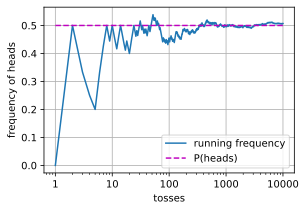

In [6]:
n = 10000
tosses = tf.cast(tf.random.uniform((n,)) < 0.5, tf.float32)  # 1 is heads
estimates = tf.cumsum(tosses) / tf.range(1, n + 1, dtype=tf.float32)
d2l.plot(tf.range(1, n + 1), [estimates, tf.fill((n,), 0.5)], 'tosses',
         'frequency of heads', legend=['running frequency', 'P(heads)'],
         xscale='log', figsize=(4.5, 3))

The running frequency swings widely at first. The swings shrink as tosses
accumulate, and after a few thousand tosses the frequency stays close to
$0.5$. That the frequency approaches the probability as the number of tosses
grows is the *law of large numbers*, which that section states
precisely and proves. The law does not say how fast the frequency
settles, which is what the coin question needs: how far from $0.5$ can the
frequency of 100 tosses lie before we should suspect the coin? To answer it,
we need a precise language for random outcomes and their averages.

## Events and Random Variables

### Sample Spaces and Events

The set of possible outcomes of a random experiment is its *sample space*
$\mathcal{S}$. For one toss of a coin,
$\mathcal{S} = \{\textrm{heads}, \textrm{tails}\}$. For one roll of a die,
$\mathcal{S} = \{1, 2, 3, 4, 5, 6\}$. For two tosses of a coin, $\mathcal{S}$
holds the four pairs (heads, heads), (heads, tails), (tails, heads), and
(tails, tails). An *event* is a subset of the sample space, and it occurs if
the outcome lies in it. For a die, "an even number" is the event
$\mathcal{A} = \{2, 4, 6\}$ and "at least 5" is the event
$\mathcal{B} = \{5, 6\}$. A roll of 6 makes both events occur; a roll of 5
makes only $\mathcal{B}$ occur.

A probability $P$ assigns a number to every event. It must obey three
rules, the axioms of @Kolmogorov.1933:

* $P(\mathcal{A}) \geq 0$ for every event $\mathcal{A}$;
* $P(\mathcal{S}) = 1$;
* if the events $\mathcal{A}_1, \mathcal{A}_2, \ldots$ are *mutually exclusive*, that is, $\mathcal{A}_i \cap \mathcal{A}_j = \emptyset$ for $i \neq j$, then the probability that one of them occurs is the sum of their probabilities, $P(\bigcup_{i} \mathcal{A}_i) = \sum_{i} P(\mathcal{A}_i)$.

Every other rule of probability follows from these three. An event
$\mathcal{A}$ and its *complement* $\mathcal{A}'$, the outcomes not in
$\mathcal{A}$, are mutually exclusive and together make up $\mathcal{S}$, so
$P(\mathcal{A}') = 1 - P(\mathcal{A})$. For $\mathcal{A} = \mathcal{S}$ this
gives $P(\emptyset) = 0$. When two events overlap, adding their probabilities
counts the outcomes that lie in both of them twice (the figure).
The union $\mathcal{A} \cup \mathcal{B}$ splits into the mutually exclusive
pieces $\mathcal{A}$ and $\mathcal{B} \setminus \mathcal{A}$, and
$P(\mathcal{B} \setminus \mathcal{A}) = P(\mathcal{B}) - P(\mathcal{A} \cap \mathcal{B})$
for the same reason. Together these give the *inclusion--exclusion* rule

$$P(\mathcal{A} \cup \mathcal{B}) = P(\mathcal{A}) + P(\mathcal{B}) - P(\mathcal{A} \cap \mathcal{B}).$$

The overlap is subtracted once because the sum counted it twice. For a fair
die, the probability of an even number or a number of at least 5 is
$3/6 + 2/6 - 1/6 = 2/3$, and indeed the union $\{2, 4, 5, 6\}$ holds four of
the six outcomes.

![Two events $\mathcal{A}$ and $\mathcal{B}$ in a sample space $\mathcal{S}$. The sum $P(\mathcal{A}) + P(\mathcal{B})$ counts the overlap $\mathcal{A} \cap \mathcal{B}$ twice.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/probability-venn.svg)

### Random Variables

Often we care about a number computed from the outcome rather than about the
outcome itself: the number of heads in 100 tosses, the sum of two dice, or
whether a classifier labels an image correctly. A *random variable* is such a
function from the sample space to a set of values. It can be much coarser
than the outcome. The number of heads in 100 tosses takes 101 values, while
the sample space holds $2^{100}$ sequences of tosses. Each value $v$ of a
random variable $X$ defines an event, the set of outcomes for which $X = v$,
so $P(X = v)$ is defined. A range of values is an event too:
$P(1 \leq X \leq 3)$ is the probability that $X$ takes a value between 1 and
3. In general, the *distribution* of $X$ assigns the probability
$P(X \in A)$ to every set $A$ of values. For a variable with finitely or
countably many values, the map $v \mapsto P(X = v)$, its *probability mass
function*, determines the distribution, and we write it as $P(X)$.

### Discrete and Continuous Variables

The random variables so far are *discrete*: they take finitely or countably
many values, each with its own probability. Many quantities are *continuous*
instead, such as the height of a person drawn at random from a population.
With fine enough measurements no two people have the same height, so the
probability that someone is exactly 1.80139278 meters tall is zero, even
though such a height is possible. The useful question is whether a height
falls into an interval, say between 1.79 and 1.81 meters. A continuous
variable has a *probability density* $p(x)$ (unrelated to the probability
$p$ of heads), and the probability of an interval is the area under the
density over it (the figure),

$$P(a \leq X \leq b) = \int_a^b p(x) \, dx.$$

Densities, and the sense in which a possible event can have probability zero,
are developed in that section. In this section we work
with discrete variables. Every sum over the values of a variable becomes an
integral when the variable has a density.

![A discrete random variable puts probability on individual values (left). A continuous random variable has a density, and the probability of an interval is the area under the density (right).](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/probability-density.svg)

## Conditional Probability

### Joint and Marginal Distributions

Most questions in machine learning involve several random variables at once:
the pixels of an image and its label, or the symptoms of a patient and the
disease. When we draw an individual from a population, each variable takes a
value, and knowing one value can change what we expect of the others. A
patient who has trouble breathing and has lost the sense of smell is more
likely to have COVID-19 than one without these symptoms.

The *joint distribution* of two random variables $A$ and $B$ assigns a
probability to every combination of values, $P(A = a, B = b)$, where the
comma means "and". the figure shows the joint distribution of a
variable $A$ with two values and a variable $B$ with three.

The joint distribution contains everything there is to know about the two
variables. In particular, it determines the distribution of each variable on
its own, its *marginal distribution*. The event $A = a$ occurs together with exactly one
value of $B$, so

$$P(A = a) = \sum_b P(A = a, B = b).$$

Summing a row of the table gives the marginal distribution of $A$, and summing
a column gives that of $B$. In the figure,
$P(A = a_2) = 0.20 + 0.15 + 0.25 = 0.60$. Removing a variable by summing over
its values is called *marginalization*. As for a single variable, $P(A, B)$
denotes the whole table, and an equation between distributions, such as
$P(A, B) = P(A) P(B)$, means that it holds for all values of the variables.

![A joint distribution $P(A, B)$ as a table. Summing a row or a column gives a marginal distribution. Dividing a row by its sum gives a conditional distribution, here $P(B \mid A = a_2)$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/probability-joint-grid.svg)

### Conditional Distributions

Suppose that we learn that $A = a_2$. Only the outcomes in the second row of
the table remain possible, and their probabilities must be rescaled so that
they sum to 1. This gives the *conditional probability* of $B = b$ given
$A = a$,

$$P(B = b \mid A = a) = \frac{P(A = a, B = b)}{P(A = a)},$$

which is defined whenever $P(A = a) > 0$. Conditioning restricts attention to
the outcomes in which $A = a$ and renormalizes. In the figure, the second row
$(0.20, 0.15, 0.25)$ becomes $(0.33, 0.25, 0.42)$. For each fixed $a$, the
conditional probabilities form a distribution over the values of $B$ and obey
all three axioms.

Multiplying both sides of the definition by $P(A = a)$ gives the
*multiplication rule*

$$P(A, B) = P(B \mid A) P(A).$$

The probability that both events occur is the probability of the first times
the probability of the second once the first is known.

### Bayes' Theorem

Often one conditional probability is easy to obtain while we need the other.
A medical study measures how often a test is positive among patients who have
a disease, $P(\textrm{positive} \mid \textrm{disease})$. A doctor facing a
positive result needs $P(\textrm{disease} \mid \textrm{positive})$. The
multiplication rule connects the two. Writing the joint distribution in both
orders, $P(A, B) = P(B \mid A) P(A) = P(A \mid B) P(B)$, and dividing by
$P(B)$ gives *Bayes' theorem* [@Bayes.1763],

$$P(A \mid B) = \frac{P(B \mid A) P(A)}{P(B)}.$$

Bayes' theorem reverses the direction of conditioning. The denominator needs
no separate measurement: marginalizing the multiplication rule over $A$ gives
$P(B) = \sum_a P(B \mid A = a) P(A = a)$, so $P(B \mid A)$ and $P(A)$
determine everything.

In inference, $A$ is a hypothesis $H$ about the world and $B$ is the data
$D$ that we observe. The *prior* $P(H)$ says how plausible the hypothesis is
before we see the data, the *likelihood* $P(D \mid H)$ says how well the
hypothesis explains the data, and the *posterior* $P(H \mid D)$ combines
the two. Since the denominator $P(D)$ is the same for every hypothesis, Bayes'
theorem reads

$$P(H \mid D) \propto P(D \mid H) P(H).$$

The posterior is proportional to the likelihood times the prior, and dividing
by the sum over all hypotheses makes it sum to 1. Probabilities used in this
way express degrees of belief rather than frequencies of repeatable events.
The rules for calculating with them are the same.

### Independence

Two random variables are *independent*, written $A \perp B$, if their joint
distribution factorizes,

$$P(A, B) = P(A) P(B).$$

Equivalently, learning the value of $B$ does not change the distribution of
$A$: $P(A \mid B = b) = P(A)$ whenever $P(B = b) > 0$. Two separate tosses of
a coin are independent, since the first toss says nothing about the second.
Independence between successive draws of data is what makes averages
reliable, as we will see when we measure how much averages fluctuate. Dependence, on the
other hand, is often what we want to learn: we predict a disease from
symptoms because the two are *not* independent.

Independence can also hold within a conditional distribution. The variables
$A$ and $B$ are *conditionally independent* given $C$, written
$A \perp B \mid C$, if $P(A, B \mid C) = P(A \mid C) P(B \mid C)$.
Conditioning can remove dependence, and it can create it
(the figure). Among elementary school students, shoe
size and reading level are strongly related, because both grow with age, their
common cause. Among students of the same age the relation disappears. In the
same way, in a chain where $A$ affects $C$ only through $B$, knowing $B$
makes $A$ irrelevant for $C$.

In the opposite direction, broken bones and lung cancer may be independent in
the general population, yet among hospital patients they are related. A
patient with a broken bone already has a reason to be in the hospital, and is
therefore less likely to be there because of lung cancer. Conditioning on a
common effect, here being in the hospital, makes its independent causes
dependent. This is called *explaining away*.

![Conditioning changes dependence. A common cause $C$ makes $A$ and $B$ dependent, and observing $C$ removes the dependence. In a chain, $A$ and $C$ are independent given $B$. A common effect $C$ makes its independent causes dependent once $C$ is observed.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/probability-explaining-away.svg)

### Example: Diagnostic Testing

A doctor administers an HIV test to a patient. The test never misses an
infection, but it reports a *false positive* for 1% of healthy patients. We
write $H \in \{0, 1\}$ for the patient's HIV status (1 for infected) and
$D_1 \in \{0, 1\}$ for the test result (1 for positive). The test is
described by conditional probabilities:

| $P(D_1 \mid H)$ | $H=1$ (HIV) | $H=0$ (healthy) |
|:--|:--:|:--:|
| test positive, $D_1 = 1$ | 1.00 | 0.01 |
| test negative, $D_1 = 0$ | 0.00 | 0.99 |

Each column is the conditional distribution of $D_1$ given one value of $H$,
so the columns sum to 1, while the rows need not. Suppose that the test comes
back positive. What is the probability $P(H = 1 \mid D_1 = 1)$ that the
patient has HIV? The answer depends on how common the disease is, since that
determines how many false alarms compete with the true detections. Assume
that 0.15% of the population is infected, $P(H=1) = 0.0015$. The denominator
of Bayes' theorem follows by marginalizing over $H$:

$$
\begin{aligned}
P(D_1 = 1)
&= P(D_1=1 \mid H=0) P(H=0) + P(D_1=1 \mid H=1) P(H=1) \\
&= 0.01 \cdot 0.9985 + 1 \cdot 0.0015 = 0.011485.
\end{aligned}
$$

Bayes' theorem then gives

$$P(H = 1 \mid D_1 = 1) = \frac{P(D_1=1 \mid H=1) P(H=1)}{P(D_1=1)} = \frac{0.0015}{0.011485} = 0.1306.$$

A patient who tests positive has HIV with a probability of only 13%, even
though the test never misses an infection and errs on just 1% of healthy
patients. the figure shows the reason in counts. Among
10,000 people, about 15 are infected and all of them test positive, but so do
about 100 of the 9,985 healthy people. Because the disease is rare, the false
positives outnumber the true ones.

![The HIV test applied to 10,000 people. The 15 infected people test positive, and so do about 100 of the 9,985 healthy people, so only 15 of about 115 positive results are correct.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/probability-natural-frequencies.svg)

A doctor would therefore order a second test. It is less accurate than the
first:

| $P(D_2 \mid H)$ | $H=1$ (HIV) | $H=0$ (healthy) |
|:--|:--:|:--:|
| test positive, $D_2 = 1$ | 0.98 | 0.03 |
| test negative, $D_2 = 0$ | 0.02 | 0.97 |

The second test comes back positive too. To combine the two results, we
assume that the tests are conditionally independent given $H$, their common
cause in the sense of the figure: once the patient's
status is known, the result of one test says nothing about the result of the
other. Then the likelihoods of the two results multiply,

$$
\begin{aligned}
P(D_1 = 1, D_2 = 1 \mid H = 0)
&= P(D_1 = 1 \mid H = 0) P(D_2 = 1 \mid H = 0) = 0.01 \cdot 0.03 = 0.0003, \\
P(D_1 = 1, D_2 = 1 \mid H = 1)
&= P(D_1 = 1 \mid H = 1) P(D_2 = 1 \mid H = 1) = 1 \cdot 0.98 = 0.98,
\end{aligned}
$$

and marginalizing over $H$ gives the probability that both tests are
positive,

$$
\begin{aligned}
P(D_1 = 1, D_2 = 1)
&= P(D_1 = 1, D_2 = 1 \mid H = 0)P(H=0) + P(D_1 = 1, D_2 = 1 \mid H = 1)P(H=1)\\
&= 0.0003 \cdot 0.9985 + 0.98 \cdot 0.0015 = 0.00176955.
\end{aligned}
$$

Bayes' theorem now gives

$$
P(H = 1 \mid D_1 = 1, D_2 = 1)
= \frac{P(D_1 = 1, D_2 = 1 \mid H=1) P(H=1)}{P(D_1 = 1, D_2 = 1)}
= \frac{0.00147}{0.00176955} = 0.8307.
$$

The second positive result raises the probability of infection from 13% to
83% (the figure). The second test is less accurate than the
first, but it still helps, because its errors are independent of those of the
first test. Without conditional independence, a second test can still help, but then we
must model the joint distribution of the two results directly. At the other
extreme, repeating a deterministic test reproduces the first result and adds
nothing. The diagnosis works like a classifier that becomes more confident as
it receives more input features, here the test results.

![The probability that the patient has HIV: the prior, after one positive test, and after two conditionally independent positive tests.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/probability-bayes-update.svg)

Since we have a complete model of how the data arise, we can check the
calculation by simulation. We draw the HIV status of two million patients,
apply both tests to each patient, and compute the fraction of infected
patients among those whose tests are both positive. Each draw compares a
uniform random number with a probability, as in our first coin toss. The
function `where` picks, for each patient, the probability that matches the
HIV status, and indexing with the mask `D1 & D2` keeps the patients whose
tests are both positive (that section).

In [7]:
n = 2000000
H = tf.random.uniform((n,)) < 0.0015
D1 = tf.random.uniform((n,)) < tf.where(H, 1.00, 0.01)
D2 = tf.random.uniform((n,)) < tf.where(H, 0.98, 0.03)
fraction = tf.reduce_mean(tf.cast(H[D1 & D2], tf.float32))
round(float(fraction), 4)  # Exact value: 0.8307

0.8344

The simulated fraction lands close to the exact value, within about two
percentage points. The agreement is looser than two million patients might
suggest, because only the few patients with two positive tests enter the
fraction. We will compute how precise the simulation is once we can measure
the fluctuations of a frequency.

## Expectation and Variance

### Expectation

A distribution lists the probability of every value. Often we need a single
number that summarizes it, such as the value to expect on average. Consider
an investment that is lost entirely with probability 0.5, doubles with
probability 0.4, and grows tenfold with probability 0.1. Weighting each return
by its probability gives the expected return
$0.5 \cdot 0 + 0.4 \cdot 2 + 0.1 \cdot 10 = 1.8$. In general, the
*expectation* or *mean* of a random variable $X$ is the average of its values
weighted by their probabilities,

$$\mathbb{E}[X] = \sum_x x \, P(X = x).$$

If we place a weight $P(X = x)$ at each position $x$ on a line, the
expectation is the point at which the line balances. For a density, the sum
becomes an integral, $\mathbb{E}[X] = \int x \, p(x) \, dx$. The expectation of a
function of $X$ is computed in the same way,
$\mathbb{E}[f(X)] = \sum_x f(x) P(X = x)$.

For a coin toss, let $X = \mathbf{1}(\textrm{heads})$ be the *indicator* of
heads: $X = 1$ if the toss comes up heads and $X = 0$ otherwise. Then
$\mathbb{E}[X] = 1 \cdot p + 0 \cdot (1 - p) = p$, so the expectation of an indicator
is the probability of its event.

Expectations can be conditioned like probabilities. The *conditional
expectation*, or conditional mean,
$\mathbb{E}[Y \mid X = x] = \sum_y y \, P(Y = y \mid X = x)$ is the average of $Y$
over the outcomes in which $X = x$. In the HIV example the status $H$ is an
indicator, so $\mathbb{E}[H \mid D_1 = 1] = P(H = 1 \mid D_1 = 1) \approx 0.13$.

Expectations are *linear*: for any
random variables $X$ and $Y$ and numbers $a$ and $b$,
$\mathbb{E}[aX + bY] = a\mathbb{E}[X] + b\mathbb{E}[Y]$. This follows by writing $\mathbb{E}[aX + bY]$ as a sum
over the joint distribution of $X$ and $Y$ and splitting the sum
(that section gives the details), and it holds whether
or not $X$ and $Y$ are independent. Let $X_i$ be the indicator of heads on
toss $i$, so that the frequency of heads is their average. Linearity gives

$$\mathbb{E}[\hat{p}] = \mathbb{E}\left[\frac{1}{n} \sum_{i=1}^n X_i\right] = \frac{1}{n} \sum_{i=1}^n \mathbb{E}[X_i] = p.$$

On average, the frequency equals the probability that it estimates; an
estimator with this property is called *unbiased*. Unbiasedness says nothing
about how far a single estimate strays from $p$, which is what the coin
question asks. For that we need a second summary.

### Variance

The investment above has an expected return of 1.8, yet half of the time it
loses everything. To measure how far values tend to fall from the mean
$\mu = \mathbb{E}[X]$, we cannot average the deviation $X - \mu$ itself, since by
linearity $\mathbb{E}[X - \mu] = \mathbb{E}[X] - \mu = 0$: positive and negative deviations
cancel. Averaging the squared deviation instead gives the *variance*,

$$\textrm{Var}(X) = \mathbb{E}\left[(X - \mu)^2\right] = \mathbb{E}[X^2] - \mu^2.$$

The second form follows by expanding $(X - \mu)^2 = X^2 - 2\mu X + \mu^2$
and taking the expectation of each term.

The variance is measured in squared units. Its square root, the *standard
deviation* $\sigma = \sqrt{\textrm{Var}(X)}$, has the units of $X$ and
measures the typical distance between $X$ and its mean. Estimated from $n$
numbers, as for the columns in that section, the variance becomes
a sum of squared deviations from their average, divided by $n$ or, to keep
the estimate unbiased when the average stands in for $\mu$, by $n - 1$.
For the investment,
$\mathbb{E}[X^2] = 0.4 \cdot 2^2 + 0.1 \cdot 10^2 = 11.6$, so
$\textrm{Var}(X) = 11.6 - 1.8^2 = 8.36$ and $\sigma \approx 2.9$, larger than
the mean itself. For the indicator of heads, $X^2 = X$, so

$$\textrm{Var}(X) = p - p^2 = p(1 - p).$$

A toss is most uncertain for a fair coin, where the variance reaches its
largest value, $1/4$. The variance is zero for a coin that always lands the
same way. Shifting a random variable by a constant $b$ does not change its
deviations from the mean, and scaling it by $a$ scales the deviations by $a$
and their squares by $a^2$, so $\textrm{Var}(aX + b) = a^2 \, \textrm{Var}(X)$.

### Sums of Independent Variables

The frequency of heads is an average of many tosses, so we need the variance
of a sum. Write $\mu_X = \mathbb{E}[X]$ and $\mu_Y = \mathbb{E}[Y]$. Expanding the square in the
definition of variance gives

$$\textrm{Var}(X + Y) = \mathbb{E}\left[(X - \mu_X + Y - \mu_Y)^2\right] = \textrm{Var}(X) + \textrm{Var}(Y) + 2\, \textrm{Cov}(X, Y),$$

where the cross term

$$\textrm{Cov}(X, Y) = \mathbb{E}\left[(X - \mu_X)(Y - \mu_Y)\right]$$

is the *covariance* of $X$ and $Y$. The covariance is positive when $X$ and
$Y$ tend to lie on the same side of their means, and negative when they tend
to lie on opposite sides (the figure).

![Samples of three pairs of random variables, with positive, near-zero, and negative covariance.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/probability-covariance.svg)

The size of the covariance depends on the units of $X$ and $Y$. Dividing by
both standard deviations gives the *correlation*
$\rho = \textrm{Cov}(X, Y) / (\sigma_X \sigma_Y)$, which has no units and
always lies between $-1$ and $1$.

For independent variables the covariance vanishes. Since the joint
distribution factorizes, the expectation of a product of a function of $X$
and a function of $Y$ factorizes too, $\mathbb{E}[f(X) g(Y)] = \mathbb{E}[f(X)] \, \mathbb{E}[g(Y)]$,
so $\textrm{Cov}(X, Y) = \mathbb{E}[X - \mu_X] \, \mathbb{E}[Y - \mu_Y] = 0$. Hence, for
independent $X$ and $Y$,

$$\textrm{Var}(X + Y) = \textrm{Var}(X) + \textrm{Var}(Y).$$

Variances of independent variables add, while standard deviations do not. The
sum of $n$ independent variables that each have variance $\sigma^2$ has
variance $n\sigma^2$ and therefore
standard deviation $\sqrt{n}\,\sigma$, not $n\sigma$, because deviations of
opposite signs partly cancel.

The converse does not hold: zero covariance does not imply independence. Let
$X$ be uniform on $\{-1, 0, 1\}$ and $Y = X^2$. Then $\mathbb{E}[X] = 0$ and
$\mathbb{E}[XY] = \mathbb{E}[X^3] = 0$, so $\textrm{Cov}(X, Y) = 0$, yet $Y$ is determined by
$X$. Covariance detects only a tendency to move together along a line.

For a random vector $\mathbf{x}$ with mean $\boldsymbol{\mu}$, the variances
and covariances of all coordinates form the *covariance matrix*

$$\boldsymbol{\Sigma} = \mathbb{E}\left[(\mathbf{x} - \boldsymbol{\mu})(\mathbf{x} - \boldsymbol{\mu})^\top\right],$$

whose diagonal holds the variances of the coordinates and whose entry
$\Sigma_{ij}$ is the covariance of $x_i$ and $x_j$. It gives the variance of
every weighted sum of the coordinates: for a fixed vector $\mathbf{v}$,
linearity of expectation yields

$$\textrm{Var}(\mathbf{v}^\top \mathbf{x}) = \mathbb{E}\left[\mathbf{v}^\top(\mathbf{x} - \boldsymbol{\mu})(\mathbf{x} - \boldsymbol{\mu})^\top \mathbf{v}\right] = \mathbf{v}^\top \boldsymbol{\Sigma} \mathbf{v}.$$

One matrix thus determines how much every weighted sum of the coordinates
fluctuates, such as the return of a portfolio of stocks or the output of a
linear model for a random input.

## Estimation Error

### The Standard Error of a Frequency

We can now compute how much the frequency of heads fluctuates. The frequency
$\hat{p} = \frac{1}{n} \sum_{i=1}^n X_i$ averages $n$ independent indicators,
each with variance $p(1 - p)$. Their sum therefore has variance $n p(1 - p)$,
and dividing the sum by $n$ multiplies its variance by $1/n^2$:

$$\textrm{Var}(\hat{p}) = \frac{p(1-p)}{n}.$$

The standard deviation of an estimate is called its *standard error*. For the
frequency of heads it is $\sqrt{p(1-p)/n}$, which for a fair coin equals
$0.5/\sqrt{n}$: $0.05$ after 100 tosses and $0.005$ after $10{,}000$. The
error falls with the square root of the number of tosses. Halving it takes
four times as many tosses, and reducing it tenfold takes a hundred times as
many. When $p$ is unknown, we substitute its estimate and use
$\sqrt{\hat{p}(1-\hat{p})/n}$, which the data alone determine.

To check the formula, we repeat the experiment many times. For each $n$, we
compute 1000 independent frequencies, each from $n$ tosses of a fair coin,
and measure their standard deviation.

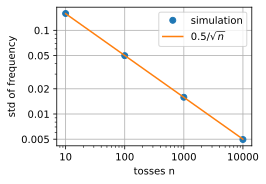

In [8]:
ns = [10, 100, 1000, 10000]
stds = [float(tf.math.reduce_std(tf.reduce_mean(
    tf.cast(tf.random.uniform((1000, n)) < 0.5, tf.float32), axis=1)))
    for n in ns]
d2l.plot(ns, [stds, [0.5 / n ** 0.5 for n in ns]], 'tosses n',
         'std of frequency', legend=['simulation', r'$0.5/\sqrt{n}$'],
         xscale='log', yscale='log', fmts=('o', '-'))

On log--log axes, the measured standard deviations lie on the predicted line
$0.5/\sqrt{n}$, whose slope is $-1/2$. The derivation used nothing about the
coin except the variance of a single toss. The average of $n$ independent
draws of any random variable with variance $\sigma^2$ has variance
$\sigma^2/n$ and standard error $\sigma/\sqrt{n}$. This rate governs every
average in this book, from the accuracy of a model on a test set to the
gradient computed on a minibatch of examples.

### Testing for Bias

We return to the 56 heads in 100 tosses. The frequency $0.56$ lies $0.06$
from $0.5$, which is $1.2$ standard errors. A fair coin produces deviations
of about one standard error all the time. To see how often it produces one at
least this large, we simulate 1000 experiments with a fair coin and count the
fraction of them whose number of heads lies at least as far from $n/2$ as the
observed count. We do this for 56 heads in 100 tosses and for the same
frequency in $10{,}000$ tosses.

In [9]:
def fraction_as_far(heads, n, num_experiments=1000):
    """Fraction of fair-coin experiments at least as far from n/2 as heads."""
    tosses = tf.random.uniform((num_experiments, n)) < 0.5
    counts = tf.reduce_sum(tf.cast(tosses, tf.float32), axis=1)
    far = tf.abs(counts - n / 2) >= abs(heads - n / 2)
    return tf.reduce_mean(tf.cast(far, tf.float64))  # no float32 print noise

float(fraction_as_far(56, 100)), float(fraction_as_far(5600, 10000))

(0.272, 0.0)

Roughly one in four fair-coin experiments with 100 tosses ends at least as
far from 50 heads as 56 does, so 56 heads give no evidence that the coin is
biased. Nor are they evidence that the coin is fair: 56 heads are just as
consistent with $p = 0.55$. They do rule out $p = 0.3$, which lies more than
five standard errors away.

The same frequency after $10{,}000$ tosses, 5,600 heads, lies
$0.06/0.005 = 12$ standard errors from $0.5$, and none of the simulated
experiments comes close to it. Deviations of many standard errors are rare
for every distribution. A random variable lies $k$ or more standard
deviations from its mean with probability at most $1/k^2$, a result known as
*Chebyshev's inequality* and proved in that section. For
$k = 12$ the bound is below 1%, and for an average of many tosses the true
probability is far smaller still. A frequency of $0.56$ is therefore
consistent with a fair coin after 100 tosses and strong evidence of bias after
$10{,}000$. What decides is the size of the deviation measured in standard
errors.

The same reasoning applies to measuring a model. Suppose that a classifier
labels each test image correctly with probability 0.9, independently of the
other images. Its accuracy on a minibatch of 256 images is then a frequency
with standard error $\sqrt{0.9 \cdot 0.1 / 256} \approx 0.019$, so two
minibatches routinely differ by a few percentage points even when nothing
has changed.
On a test set of $10{,}000$ images, the standard error drops to $0.003$, and
a difference of one percentage point between two models is unlikely to be
noise.

The standard error also tells us how far to trust the HIV simulation. Of the
two million simulated patients, only about
$2{,}000{,}000 \cdot 0.00177 \approx 3{,}500$ test positive twice, and the
simulated posterior is a frequency over these patients. Its standard error is
$\sqrt{0.83 \cdot 0.17 / 3500} \approx 0.006$, consistent with the agreement
we observed. One more correct digit would take a hundred times as many
patients.

### Aleatoric and Epistemic Uncertainty

The standard error measures our uncertainty about $p$, and it shrinks as
tosses accumulate. Our uncertainty about the next toss does not shrink: even
if we knew that $p = 0.5$ exactly, the next toss would come up heads only
half of the time. The two kinds of uncertainty have names
[@Der-Kiureghian.Ditlevsen.2009]. *Epistemic uncertainty* is uncertainty
about the model, such as the value of $p$, and more data reduces it.
*Aleatoric uncertainty* is randomness in the outcome itself, which remains
even when the model is known exactly. A classifier trained on ever more
images becomes more certain of the probabilities it assigns, but for an
image that is ambiguous, such as a blurry photograph that could
show a shirt or a coat, those probabilities stay spread out. More data
reduces the epistemic part, at the slow rate of $1/\sqrt{n}$. The aleatoric
part sets a floor that no amount of data can remove.

We can now compute with probabilities, reverse a conditional with Bayes'
theorem, and attach a standard error to an average, which separates a stable
pattern from sampling noise. Throughout this section the probabilities were
given: a fair coin, or a test with known error rates. In learning they are
unknown, and a model with many parameters must estimate them from data.
that section begins with the simplest such model.

## Summary

Probability describes how a random process generates data, and statistics
reasons back from the data to the process. Probabilities obey three axioms;
marginalizing sums over the values of a variable, and conditioning restricts
attention to the outcomes consistent with what we know and renormalizes.
Bayes' theorem reverses a conditional: a positive result from an accurate test
for a rare disease leaves the disease unlikely (13%), and a second,
conditionally independent positive raises it to 83%. Expectation and variance
summarize a distribution, and since variances of independent variables add,
the average of $n$ independent draws has standard error $\sigma/\sqrt{n}$.
Deviations of one or two standard errors are what chance routinely produces,
while many standard errors signal a real effect: 56 heads in 100 tosses are
consistent with a fair coin, but 5,600 heads in $10{,}000$ tosses are strong
evidence of bias.

## Exercises

1. **Two kinds of uncertainty.** Give two examples of prediction tasks other
   than coin tossing. Choose the first so that more data can reduce the
   uncertainty about the outcome to any level, and the second so that it
   cannot. For each, state which part of the uncertainty is aleatoric and which
   is epistemic, and explain what sets the floor in the second example.
1. [code] **Chebyshev for the coin-toss estimator.**
   the equation gives the variance of the frequency $\hat{p}$
   of heads after $n$ tosses.
    1. For a fair coin and $n = 100$, use Chebyshev's inequality to bound
       $P(|\hat{p} - p| \geq 0.1)$.
    1. Estimate the same probability by simulating 10,000 repetitions of
       100 tosses, compare it with the bound, and account for the gap.
    1. Determine how many tosses Chebyshev's inequality requires to
       guarantee $P(|\hat{p} - p| \geq 0.01) \leq 0.05$ for a fair coin,
       and compare with the $n$ at which the standard error
       $\sqrt{p(1-p)/n}$ itself equals $0.01$.
1. **Union and intersection bounds.** Given two events with probabilities
   $P(\mathcal{A})$ and $P(\mathcal{B})$, derive the tightest upper and
   lower bounds on $P(\mathcal{A} \cup \mathcal{B})$ and
   $P(\mathcal{A} \cap \mathcal{B})$, and describe the configurations in
   the figure for which each bound is attained.
1. **Factorizing a chain.** Let $A$, $B$, and $C$ be random variables such
   that $C$ is conditionally independent of $A$ given $B$, as in the chain
   of the figure.
    1. Write the joint probability $P(A, B, C)$ as a product of factors that
       each involve at most two of the variables.
    1. Generalize to a sequence $X_1, \ldots, X_T$ in which each $X_t$
       depends on the earlier variables only through $X_{t-1}$. How many
       numbers specify the joint distribution if every $X_t$ takes $k$
       values, compared with an arbitrary joint distribution of $T$ such
       variables?
1. **Conditioning on a common effect.** Toss two independent fair coins, and
   let $A, B \in \{0, 1\}$ indicate heads on each. Let $C = \max(A, B)$
   indicate that at least one coin came up heads. Compute $P(A = 1)$,
   $P(A = 1 \mid C = 1)$, and $P(A = 1 \mid C = 1, B = 1)$. Use these values
   to decide whether $A$ and $B$ are conditionally independent given
   $C = 1$, and relate the change from the second value to the third
   to the figure.
1. **A second, correlated test.** ● Revisit
   that section with two new tests whose outcomes
   are conditionally independent for patients with HIV but not for
   healthy patients. Either test on its own has a false positive rate of
   10% and a false negative rate of 1%:

   $$P(D_i = 1 \mid H = 0) = 0.1, \quad P(D_i = 0 \mid H = 1) = 0.01 \quad \textrm{for } i = 1, 2.$$

   For $H = 1$, the joint distribution factorizes as
   $P(D_1, D_2 \mid H = 1) = P(D_1 \mid H = 1)\, P(D_2 \mid H = 1)$. For
   $H = 0$, the outcomes are coupled through
   $P(D_1 = D_2 = 1 \mid H = 0) = 0.02$. The baseline probability is
   $P(H = 1) = 0.0015$ as before.
    1. Work out the joint probability table for $D_1$ and $D_2$ given
       $H = 0$.
    1. Derive the probability that the patient has HIV after the first
       test returns positive, before the second test is run.
    1. Derive the probability that the patient has HIV after both tests
       return positive.
    1. Repeat the previous calculation for tests that are conditionally
       independent given $H = 0$ as well, and explain why the two
       posteriors differ.
1. **Comparing two classifiers.** ● Two classifiers are evaluated on the same
   test set of $n = 10{,}000$ images. Classifier A labels 9,050 images
   correctly and classifier B labels 9,000 correctly. Treat the test images
   as independent draws.
    1. Compute the standard error of each accuracy.
    1. Assume that the two accuracies are independent and compute the
       standard error of their difference. Is the difference of $0.005$
       large compared with the noise?
    1. The two accuracies are measured on the same images, so they are not
       independent. Suppose that the classifiers disagree on 300 images,
       A being correct on 175 of them and B on 125. For image $i$, let
       $Z_i = 1$ if only A is correct, $Z_i = -1$ if only B is correct, and
       $Z_i = 0$ otherwise, so that the difference in accuracy is the average
       of the $Z_i$. Compute the standard error of this average and compare
       it with your answer to the previous part.
    1. Use $\textrm{Var}(X - Y) = \textrm{Var}(X) + \textrm{Var}(Y) - 2\,\textrm{Cov}(X, Y)$
       to explain the difference. What sign does the covariance between the
       two classifiers' correctness on an image have, and why?
1. **Portfolio return and risk.** Assume that you manage a portfolio of
   $n$ stocks whose returns $\mathbf{s} \in \mathbb{R}^n$ are random with
   mean $\boldsymbol{\mu} = \mathbb{E}[\mathbf{s}]$ and covariance matrix
   $\boldsymbol{\Sigma}$. You invest a fraction $\alpha_i \geq 0$ of your
   capital in stock $i$, with $\sum_i \alpha_i = 1$.
    1. Compute the expected return and the variance of the return of the
       portfolio $\boldsymbol{\alpha}$.
    1. Assume that every stock has variance $\sigma^2$ and that every pair
       of distinct stocks has correlation $\rho \geq 0$. Compute the
       variance of the equally weighted portfolio $\alpha_i = 1/n$ and its
       limit as $n \to \infty$. Compare the case $\rho = 0$
       with the equation.
    1. Formulate an optimization problem that maximizes the expected
       return while constraining the variance to an upper bound. This is
       the [Markowitz portfolio](https://en.wikipedia.org/wiki/Markowitz_model)
       problem [@Mangram.2013]. Methods for constrained problems of
       this kind are developed
       in that section.
1. **A defense lawyer's statistics.** A suspect had a documented history of
   abusing his now-murdered wife. His lawyer argues that, statistically,
   only one in a thousand wife-abusers goes on to murder his wife, so the
   history of abuse is weak evidence and the jury should acquit. Write
   $M$ for "the suspect murdered his wife," $K$ for "his wife was killed,"
   and $B$ for "he had a history of abusing her."
    1. Express the lawyer's one-in-a-thousand figure and the posterior
       probability of guilt in these terms, and identify which probability
       the lawyer has confused with which.
    1. Assume that, over the time span the lawyer's statistic refers to, an
       abused wife is murdered by someone other than her husband with
       probability $10^{-5}$. Compute the posterior probability of guilt and
       compare it with the lawyer's figure.

    *Adapted from MIT 18.05,
    [problem set 7](https://ocw.mit.edu/courses/18-05-introduction-to-probability-and-statistics-spring-2022/mit18_05_s22_pset07_sol.pdf),
    Problem 4.*

[Discussions](https://d2l.discourse.group/t/198)